# Logistic Regression Baseline for UFC Winner Prediction

This notebook builds a baseline logistic regression model using the processed fight datasets.

## Imports: Libraries Used in This Notebook

This code block imports all required packages for:
1. Data loading and manipulation (`pandas`).
2. Plotting (`matplotlib`, `seaborn`).
3. Model building (`Pipeline`, `StandardScaler`, `LogisticRegression`).
4. Model evaluation (`accuracy`, `precision`, `recall`, `F1`, `ROC-AUC`, confusion matrix, and classification report).
5. Saving trained models (`joblib`).

In [23]:
# Imports
from pathlib import Path

import numpy as np

import joblib
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
)

## Paths and Data Loading

This code block defines project/data/model paths and reads train, validation, validation_exp1, validation_exp2, test, test_exp1, and test_exp2 processed CSV files.

In [24]:
# Paths
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = DATA_DIR / "Logistic_Regression_Outputs"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

train_path = DATA_DIR / "fights_training.csv"
val_path = DATA_DIR / "fights_validation.csv"
val_exp1_path = DATA_DIR / "fights_validation_exp1.csv"
val_exp2_path = DATA_DIR / "fights_validation_exp2.csv"
test_path = DATA_DIR / "fights_testing.csv"
test_exp1_path = DATA_DIR / "fights_testing_exp1.csv"
test_exp2_path = DATA_DIR / "fights_testing_exp2.csv"

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
val_exp1_df = pd.read_csv(val_exp1_path)
val_exp2_df = pd.read_csv(val_exp2_path)
test_df = pd.read_csv(test_path)
test_exp1_df = pd.read_csv(test_exp1_path)
test_exp2_df = pd.read_csv(test_exp2_path)


## Define Target Column and the Feature Columns and Split Each Data Frame to X and Y


In [25]:
TARGET = "winner"
dob = "diff_fighter_dob"
features = [col for col in train_df.columns if col != TARGET]

x_train = train_df[features]
y_train = train_df[TARGET]

x_val = val_df.reindex(columns=features, fill_value=0)
y_val = val_df[TARGET]

x_val_exp1 = val_exp1_df.reindex(columns=features, fill_value=0)
y_val_exp1 = val_exp1_df[TARGET]

x_val_exp2 = val_exp2_df.reindex(columns=features, fill_value=0)
y_val_exp2 = val_exp2_df[TARGET]

x_test = test_df.reindex(columns=features, fill_value=0)
y_test = test_df[TARGET]

x_test_exp1 = test_exp1_df.reindex(columns=features, fill_value=0)
y_test_exp1 = test_exp1_df[TARGET]

x_test_exp2 = test_exp2_df.reindex(columns=features, fill_value=0)
y_test_exp2 = test_exp2_df[TARGET]


## Build Scikit-Learn Pipline
1. Standarize data to ensure each feature has a mean of zero and a standard deviation of 1 (Standard Scalar)
2. Perform Logistic Regression

In [ ]:
pipeline = Pipeline(steps=[("scaler", StandardScaler()),
    ("log_reg", LogisticRegression(random_state=42, max_iter=2000))])
pipeline.fit(x_train, y_train)
val_pred = pipeline.predict(x_val)
val_prob = pipeline.predict_proba(x_val)[:, 1]
val_exp1_pred = pipeline.predict(x_val_exp1)
val_exp1_prob = pipeline.predict_proba(x_val_exp1)[:, 1]
val_exp2_pred = pipeline.predict(x_val_exp2)
val_exp2_prob = pipeline.predict_proba(x_val_exp2)[:, 1]

# Test predictions
test_pred = pipeline.predict(x_test)
test_prob = pipeline.predict_proba(x_test)[:, 1]
test_exp1_pred = pipeline.predict(x_test_exp1)
test_exp1_prob = pipeline.predict_proba(x_test_exp1)[:, 1]
test_exp2_pred = pipeline.predict(x_test_exp2)
test_exp2_prob = pipeline.predict_proba(x_test_exp2)[:, 1]


In [27]:
# Save split-level predictions and probabilities to CSV
validation_output_path = OUTPUT_DIR / "logistic_regression_validation_predictions.csv"
validation_exp1_output_path = OUTPUT_DIR / "logistic_regression_validation_exp1_predictions.csv"
validation_exp2_output_path = OUTPUT_DIR / "logistic_regression_validation_exp2_predictions.csv"
test_output_path = OUTPUT_DIR / "logistic_regression_test_predictions.csv"
test_exp1_output_path = OUTPUT_DIR / "logistic_regression_test_exp1_predictions.csv"
test_exp2_output_path = OUTPUT_DIR / "logistic_regression_test_exp2_predictions.csv"

validation_results = x_val.reset_index(drop=True).copy()
validation_results["actual_label"] = y_val.reset_index(drop=True)
validation_results["predicted_label"] = val_pred
validation_results["prob_fighter_a_win"] = val_prob
validation_results["prob_fighter_b_win"] = 1 - val_prob
validation_results["correct"] = (validation_results["actual_label"] == validation_results["predicted_label"]).astype(int)

validation_exp1_results = x_val_exp1.reset_index(drop=True).copy()
validation_exp1_results["actual_label"] = y_val_exp1.reset_index(drop=True)
validation_exp1_results["predicted_label"] = val_exp1_pred
validation_exp1_results["prob_fighter_a_win"] = val_exp1_prob
validation_exp1_results["prob_fighter_b_win"] = 1 - val_exp1_prob
validation_exp1_results["correct"] = (validation_exp1_results["actual_label"] == validation_exp1_results["predicted_label"]).astype(int)

validation_exp2_results = x_val_exp2.reset_index(drop=True).copy()
validation_exp2_results["actual_label"] = y_val_exp2.reset_index(drop=True)
validation_exp2_results["predicted_label"] = val_exp2_pred
validation_exp2_results["prob_fighter_a_win"] = val_exp2_prob
validation_exp2_results["prob_fighter_b_win"] = 1 - val_exp2_prob
validation_exp2_results["correct"] = (validation_exp2_results["actual_label"] == validation_exp2_results["predicted_label"]).astype(int)

test_results = x_test.reset_index(drop=True).copy()
test_results["actual_label"] = y_test.reset_index(drop=True)
test_results["predicted_label"] = test_pred
test_results["prob_fighter_a_win"] = test_prob
test_results["prob_fighter_b_win"] = 1 - test_prob
test_results["correct"] = (test_results["actual_label"] == test_results["predicted_label"]).astype(int)

test_exp1_results = x_test_exp1.reset_index(drop=True).copy()
test_exp1_results["actual_label"] = y_test_exp1.reset_index(drop=True)
test_exp1_results["predicted_label"] = test_exp1_pred
test_exp1_results["prob_fighter_a_win"] = test_exp1_prob
test_exp1_results["prob_fighter_b_win"] = 1 - test_exp1_prob
test_exp1_results["correct"] = (test_exp1_results["actual_label"] == test_exp1_results["predicted_label"]).astype(int)

test_exp2_results = x_test_exp2.reset_index(drop=True).copy()
test_exp2_results["actual_label"] = y_test_exp2.reset_index(drop=True)
test_exp2_results["predicted_label"] = test_exp2_pred
test_exp2_results["prob_fighter_a_win"] = test_exp2_prob
test_exp2_results["prob_fighter_b_win"] = 1 - test_exp2_prob
test_exp2_results["correct"] = (test_exp2_results["actual_label"] == test_exp2_results["predicted_label"]).astype(int)

validation_results.to_csv(validation_output_path, index=False)
validation_exp1_results.to_csv(validation_exp1_output_path, index=False)
validation_exp2_results.to_csv(validation_exp2_output_path, index=False)
test_results.to_csv(test_output_path, index=False)
test_exp1_results.to_csv(test_exp1_output_path, index=False)
test_exp2_results.to_csv(test_exp2_output_path, index=False)

print(f"Saved validation predictions to: {validation_output_path}")
print(f"Saved validation exp1 predictions to: {validation_exp1_output_path}")
print(f"Saved validation exp2 predictions to: {validation_exp2_output_path}")
print(f"Saved test predictions to: {test_output_path}")
print(f"Saved test exp1 predictions to: {test_exp1_output_path}")
print(f"Saved test exp2 predictions to: {test_exp2_output_path}")

Saved validation predictions to: /Users/andrewmattei/Machine-Learning-Project/data/processed/Logistic_Regression_Outputs/logistic_regression_validation_predictions.csv
Saved validation exp1 predictions to: /Users/andrewmattei/Machine-Learning-Project/data/processed/Logistic_Regression_Outputs/logistic_regression_validation_exp1_predictions.csv
Saved validation exp2 predictions to: /Users/andrewmattei/Machine-Learning-Project/data/processed/Logistic_Regression_Outputs/logistic_regression_validation_exp2_predictions.csv
Saved test predictions to: /Users/andrewmattei/Machine-Learning-Project/data/processed/Logistic_Regression_Outputs/logistic_regression_test_predictions.csv
Saved test exp1 predictions to: /Users/andrewmattei/Machine-Learning-Project/data/processed/Logistic_Regression_Outputs/logistic_regression_test_exp1_predictions.csv
Saved test exp2 predictions to: /Users/andrewmattei/Machine-Learning-Project/data/processed/Logistic_Regression_Outputs/logistic_regression_test_exp2_pred

## Metrics and Classification Reports

This code block computes metrics (accuracy, precision, recall, F1, log loss, and ROC-AUC) for validation, validation_exp1, validation_exp2, test, test_exp1, and test_exp2 splits, then prints class-by-class reports.

In [28]:
val_metrics = {
    "accuracy": accuracy_score(y_val, val_pred),
    "precision": precision_score(y_val, val_pred, zero_division=0),
    "recall": recall_score(y_val, val_pred, zero_division=0),
    "f1": f1_score(y_val, val_pred, zero_division=0),
    "log_loss": log_loss(y_val, val_prob),
    "roc_auc": roc_auc_score(y_val, val_prob),
}

val_exp1_metrics = {
    "accuracy": accuracy_score(y_val_exp1, val_exp1_pred),
    "precision": precision_score(y_val_exp1, val_exp1_pred, zero_division=0),
    "recall": recall_score(y_val_exp1, val_exp1_pred, zero_division=0),
    "f1": f1_score(y_val_exp1, val_exp1_pred, zero_division=0),
    "log_loss": log_loss(y_val_exp1, val_exp1_prob),
    "roc_auc": roc_auc_score(y_val_exp1, val_exp1_prob),
}

val_exp2_metrics = {
    "accuracy": accuracy_score(y_val_exp2, val_exp2_pred),
    "precision": precision_score(y_val_exp2, val_exp2_pred, zero_division=0),
    "recall": recall_score(y_val_exp2, val_exp2_pred, zero_division=0),
    "f1": f1_score(y_val_exp2, val_exp2_pred, zero_division=0),
    "log_loss": log_loss(y_val_exp2, val_exp2_prob),
    "roc_auc": roc_auc_score(y_val_exp2, val_exp2_prob),
}

test_metrics = {
    "accuracy": accuracy_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred, zero_division=0),
    "recall": recall_score(y_test, test_pred, zero_division=0),
    "f1": f1_score(y_test, test_pred, zero_division=0),
    "log_loss": log_loss(y_test, test_prob),
    "roc_auc": roc_auc_score(y_test, test_prob),
}

test_exp1_metrics = {
    "accuracy": accuracy_score(y_test_exp1, test_exp1_pred),
    "precision": precision_score(y_test_exp1, test_exp1_pred, zero_division=0),
    "recall": recall_score(y_test_exp1, test_exp1_pred, zero_division=0),
    "f1": f1_score(y_test_exp1, test_exp1_pred, zero_division=0),
    "log_loss": log_loss(y_test_exp1, test_exp1_prob),
    "roc_auc": roc_auc_score(y_test_exp1, test_exp1_prob),
}

test_exp2_metrics = {
    "accuracy": accuracy_score(y_test_exp2, test_exp2_pred),
    "precision": precision_score(y_test_exp2, test_exp2_pred, zero_division=0),
    "recall": recall_score(y_test_exp2, test_exp2_pred, zero_division=0),
    "f1": f1_score(y_test_exp2, test_exp2_pred, zero_division=0),
    "log_loss": log_loss(y_test_exp2, test_exp2_prob),
    "roc_auc": roc_auc_score(y_test_exp2, test_exp2_prob),
}

metrics_df = pd.DataFrame(
    [
        val_metrics,
        val_exp1_metrics,
        val_exp2_metrics,
        test_metrics,
        test_exp1_metrics,
        test_exp2_metrics,
    ],
    index=[
        "validation",
        "validation_exp1",
        "validation_exp2",
        "test",
        "test_exp1",
        "test_exp2",
    ],
)
display(metrics_df)

print("\nValidation classification report:")
print(classification_report(y_val, val_pred, digits=4))

print("\nValidation exp1 classification report:")
print(classification_report(y_val_exp1, val_exp1_pred, digits=4))

print("\nValidation exp2 classification report:")
print(classification_report(y_val_exp2, val_exp2_pred, digits=4))

print("\nTest classification report:")
print(classification_report(y_test, test_pred, digits=4))

print("\nTest exp1 classification report:")
print(classification_report(y_test_exp1, test_exp1_pred, digits=4))

print("\nTest exp2 classification report:")
print(classification_report(y_test_exp2, test_exp2_pred, digits=4))

,accuracy,precision,recall,f1,log_loss,roc_auc
validation,0.572233,0.572233,0.572233,0.572233,0.684817,0.624357
validation_exp1,0.625263,0.625263,0.625263,0.625263,0.645191,0.676889
validation_exp2,0.620968,0.620968,0.620968,0.620968,0.646272,0.673626
test,0.622659,0.622659,0.622659,0.622659,0.658194,0.653159
test_exp1,0.607368,0.607368,0.607368,0.607368,0.656544,0.650266
test_exp2,0.607239,0.607239,0.607239,0.607239,0.654178,0.655192



Validation classification report:
              precision    recall  f1-score   support

           0     0.5722    0.5722    0.5722       533
           1     0.5722    0.5722    0.5722       533

    accuracy                         0.5722      1066
   macro avg     0.5722    0.5722    0.5722      1066
weighted avg     0.5722    0.5722    0.5722      1066


Validation exp1 classification report:
              precision    recall  f1-score   support

           0     0.6253    0.6253    0.6253       475
           1     0.6253    0.6253    0.6253       475

    accuracy                         0.6253       950
   macro avg     0.6253    0.6253    0.6253       950
weighted avg     0.6253    0.6253    0.6253       950


Validation exp2 classification report:
              precision    recall  f1-score   support

           0     0.6210    0.6210    0.6210       372
           1     0.6210    0.6210    0.6210       372

    accuracy                         0.6210       744
   macro avg 

## Cross-Entropy Evaluation and Visualization

This section computes per-fight cross entropy from the predicted probabilities and compares distributions in two separate groups:
1. Validation splits (`validation`, `validation_exp1`, `validation_exp2`)
2. Test splits (`test`, `test_exp1`, `test_exp2`)

Lower values indicate better calibrated predictions.

,split,mean,median,std
0,test,0.658194,0.611052,0.282353
1,test_exp1,0.656544,0.625097,0.246170
2,test_exp2,0.654178,0.619855,0.253348
3,validation,0.684817,0.638743,0.409997
4,validation_exp1,0.645191,0.615137,0.243370
5,validation_exp2,0.646272,0.615830,0.244527


/var/folders/ll/p6v0dbfd42s1q36h2j0fz5kw0000gn/T/ipykernel_99719/2385771214.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


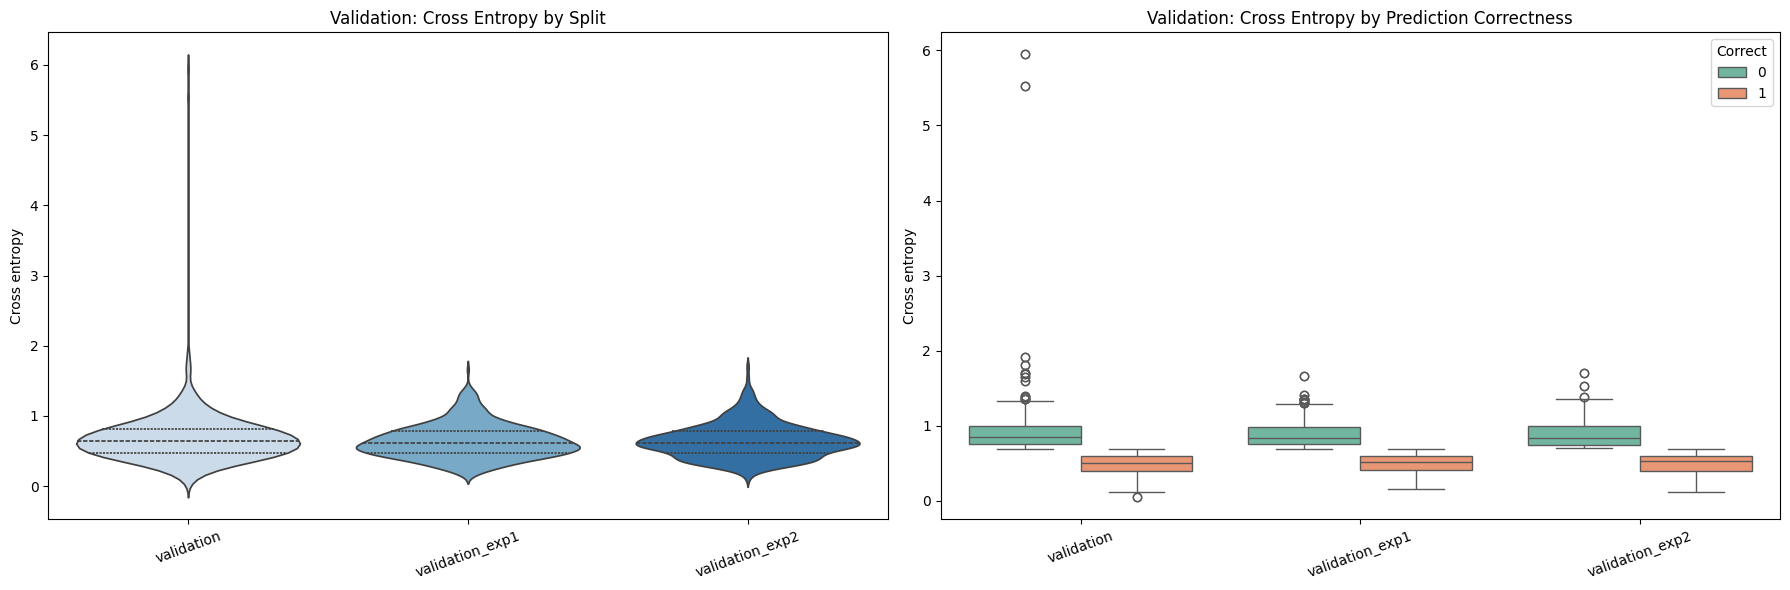

/var/folders/ll/p6v0dbfd42s1q36h2j0fz5kw0000gn/T/ipykernel_99719/2385771214.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


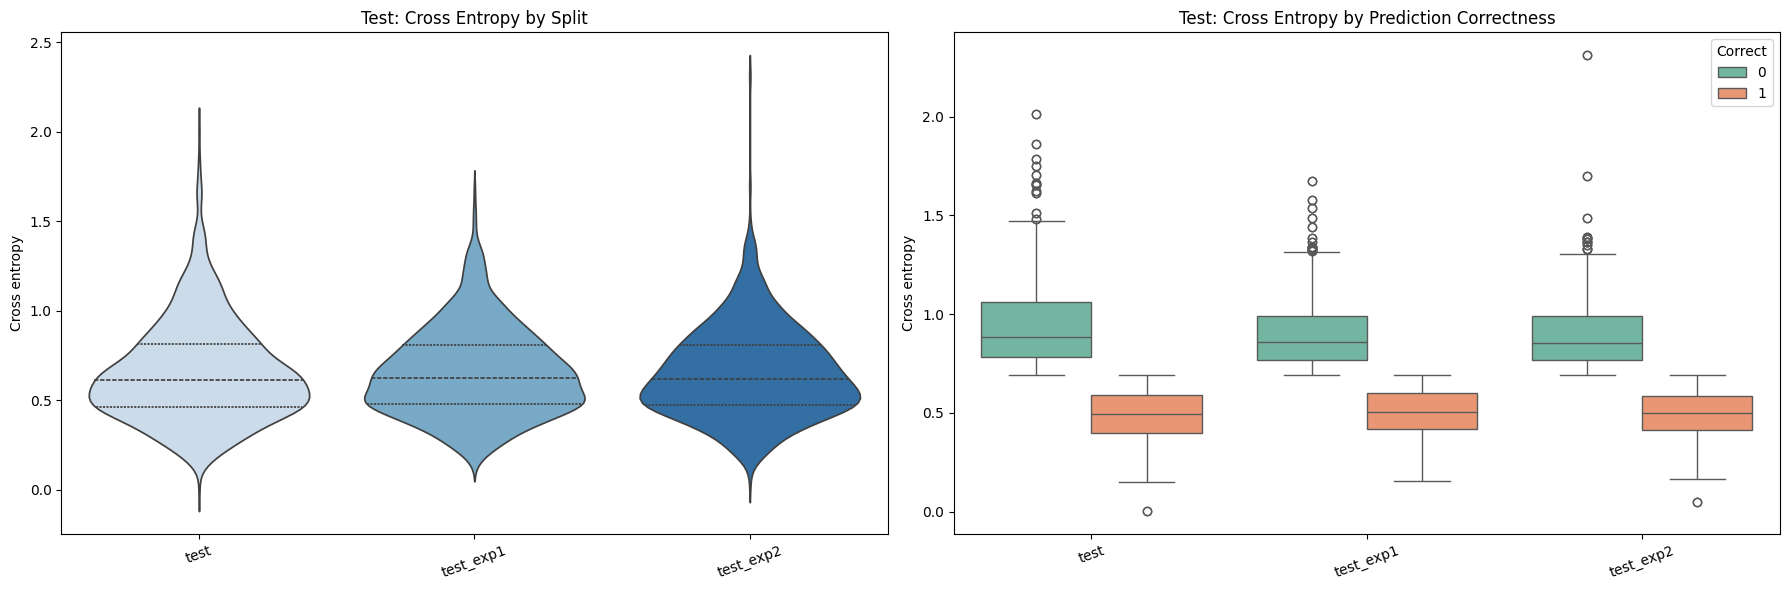

In [29]:
def binary_cross_entropy(y_true, y_prob):
    y_true_arr = np.asarray(y_true, dtype=float)
    y_prob_arr = np.clip(np.asarray(y_prob, dtype=float), 1e-15, 1 - 1e-15)
    return -(y_true_arr * np.log(y_prob_arr) + (1 - y_true_arr) * np.log(1 - y_prob_arr))


def build_ce_frame(split_name, y_true, y_pred, y_prob):
    frame = pd.DataFrame({
        "split": split_name,
        "actual_label": y_true.reset_index(drop=True),
        "predicted_label": y_pred,
        "prob_fighter_a_win": y_prob,
    })
    frame["cross_entropy"] = binary_cross_entropy(frame["actual_label"], frame["prob_fighter_a_win"])
    frame["correct"] = (frame["actual_label"] == frame["predicted_label"]).astype(int)
    return frame


validation_ce = build_ce_frame("validation", y_val, val_pred, val_prob)
validation_exp1_ce = build_ce_frame("validation_exp1", y_val_exp1, val_exp1_pred, val_exp1_prob)
validation_exp2_ce = build_ce_frame("validation_exp2", y_val_exp2, val_exp2_pred, val_exp2_prob)
test_ce = build_ce_frame("test", y_test, test_pred, test_prob)
test_exp1_ce = build_ce_frame("test_exp1", y_test_exp1, test_exp1_pred, test_exp1_prob)
test_exp2_ce = build_ce_frame("test_exp2", y_test_exp2, test_exp2_pred, test_exp2_prob)

ce_df = pd.concat(
    [validation_ce, validation_exp1_ce, validation_exp2_ce, test_ce, test_exp1_ce, test_exp2_ce],
    ignore_index=True,
)
summary_df = ce_df.groupby("split")["cross_entropy"].agg(["mean", "median", "std"]).reset_index()
display(summary_df)


def plot_cross_entropy_by_group(dataframe, split_order, group_title):
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))

    sns.violinplot(
        data=dataframe,
        x="split",
        y="cross_entropy",
        order=split_order,
        inner="quartile",
        palette="Blues",
        ax=axes[0],
    )
    axes[0].set_title(f"{group_title}: Cross Entropy by Split")
    axes[0].set_xlabel("")
    axes[0].set_ylabel("Cross entropy")
    axes[0].tick_params(axis="x", rotation=20)

    sns.boxplot(
        data=dataframe,
        x="split",
        y="cross_entropy",
        hue="correct",
        order=split_order,
        palette="Set2",
        ax=axes[1],
    )
    axes[1].set_title(f"{group_title}: Cross Entropy by Prediction Correctness")
    axes[1].set_xlabel("")
    axes[1].set_ylabel("Cross entropy")
    axes[1].tick_params(axis="x", rotation=20)
    axes[1].legend(title="Correct", loc="upper right")

    plt.tight_layout()
    plt.show()


validation_splits = ["validation", "validation_exp1", "validation_exp2"]
test_splits = ["test", "test_exp1", "test_exp2"]

plot_cross_entropy_by_group(
    ce_df[ce_df["split"].isin(validation_splits)],
    validation_splits,
    "Validation",
)
plot_cross_entropy_by_group(
    ce_df[ce_df["split"].isin(test_splits)],
    test_splits,
    "Test",
)

## ROC-AUC Evaluation and ROC Curves

This section reports ROC-AUC for all splits and plots ROC curves in two separate figures:
1. Validation splits (`validation`, `validation_exp1`, `validation_exp2`)
2. Test splits (`test`, `test_exp1`, `test_exp2`)

Curves closer to the top-left corner indicate stronger class separation.

Validation ROC-AUC: 0.6244
Validation exp1 ROC-AUC: 0.6769
Validation exp2 ROC-AUC: 0.6736
Test ROC-AUC: 0.6532
Test exp1 ROC-AUC: 0.6503
Test exp2 ROC-AUC: 0.6552


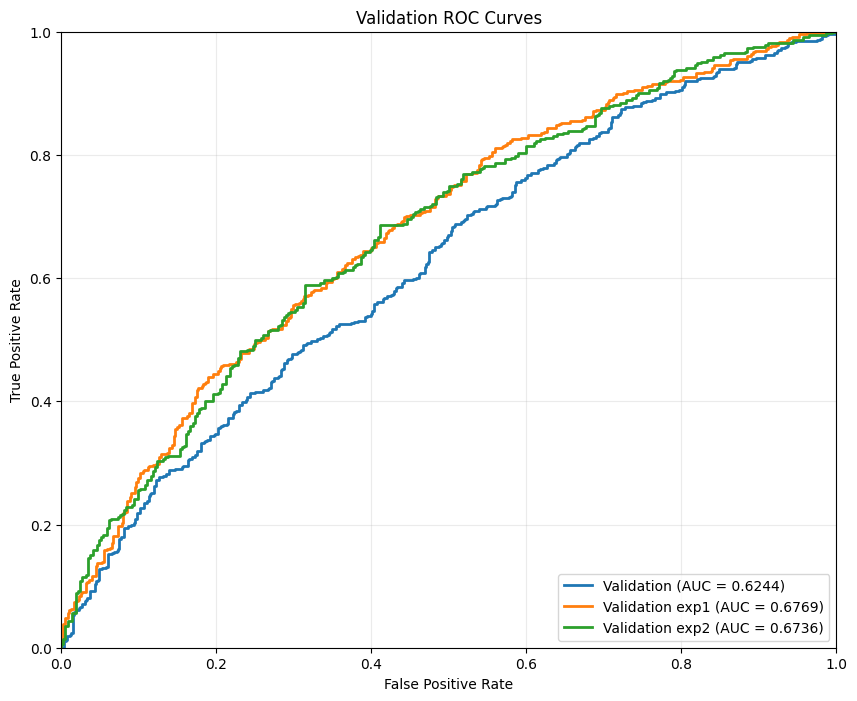

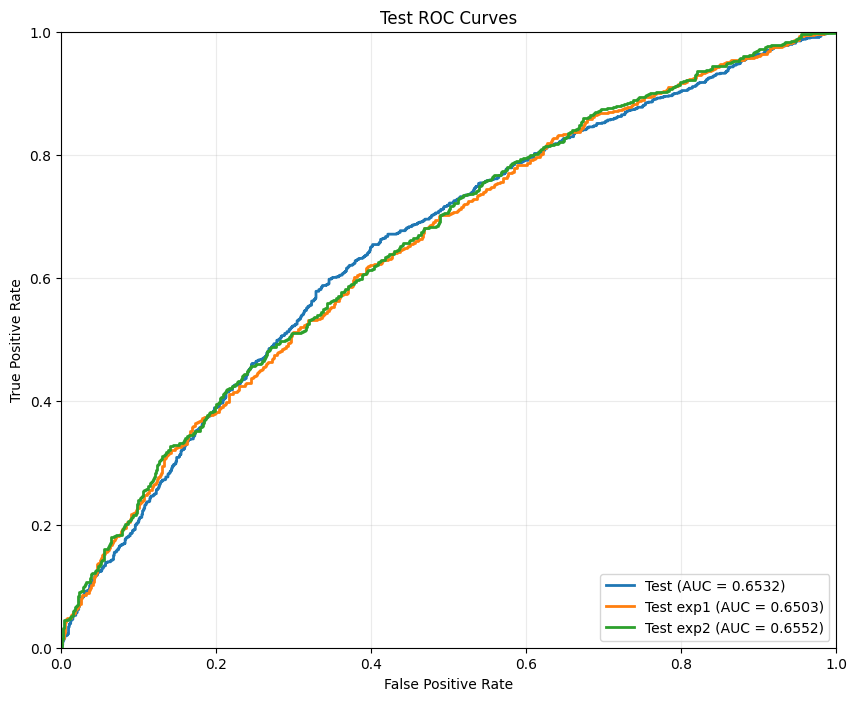

In [30]:
val_auc = roc_auc_score(y_val, val_prob)
val_exp1_auc = roc_auc_score(y_val_exp1, val_exp1_prob)
val_exp2_auc = roc_auc_score(y_val_exp2, val_exp2_prob)
test_auc = roc_auc_score(y_test, test_prob)
test_exp1_auc = roc_auc_score(y_test_exp1, test_exp1_prob)
test_exp2_auc = roc_auc_score(y_test_exp2, test_exp2_prob)

print(f"Validation ROC-AUC: {val_auc:.4f}")
print(f"Validation exp1 ROC-AUC: {val_exp1_auc:.4f}")
print(f"Validation exp2 ROC-AUC: {val_exp2_auc:.4f}")
print(f"Test ROC-AUC: {test_auc:.4f}")
print(f"Test exp1 ROC-AUC: {test_exp1_auc:.4f}")
print(f"Test exp2 ROC-AUC: {test_exp2_auc:.4f}")

val_fpr, val_tpr, _ = roc_curve(y_val, val_prob)
val_exp1_fpr, val_exp1_tpr, _ = roc_curve(y_val_exp1, val_exp1_prob)
val_exp2_fpr, val_exp2_tpr, _ = roc_curve(y_val_exp2, val_exp2_prob)
test_fpr, test_tpr, _ = roc_curve(y_test, test_prob)
test_exp1_fpr, test_exp1_tpr, _ = roc_curve(y_test_exp1, test_exp1_prob)
test_exp2_fpr, test_exp2_tpr, _ = roc_curve(y_test_exp2, test_exp2_prob)

plt.figure(figsize=(10, 8))
plt.plot(val_fpr, val_tpr, linewidth=2, label=f"Validation (AUC = {val_auc:.4f})")
plt.plot(val_exp1_fpr, val_exp1_tpr, linewidth=2, label=f"Validation exp1 (AUC = {val_exp1_auc:.4f})")
plt.plot(val_exp2_fpr, val_exp2_tpr, linewidth=2, label=f"Validation exp2 (AUC = {val_exp2_auc:.4f})")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Validation ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.show()

plt.figure(figsize=(10, 8))
plt.plot(test_fpr, test_tpr, linewidth=2, label=f"Test (AUC = {test_auc:.4f})")
plt.plot(test_exp1_fpr, test_exp1_tpr, linewidth=2, label=f"Test exp1 (AUC = {test_exp1_auc:.4f})")
plt.plot(test_exp2_fpr, test_exp2_tpr, linewidth=2, label=f"Test exp2 (AUC = {test_exp2_auc:.4f})")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Test ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.show()

## Evaluation and Coefficient Interpretation

The next code block does two things:
1. Plots confusion matrices for validation, validation_exp1, validation_exp2, test, test_exp1, and test_exp2 so you can compare true/false predictions by class across splits.
2. Extracts logistic regression coefficients and displays the top features by absolute magnitude to highlight the strongest model signals.

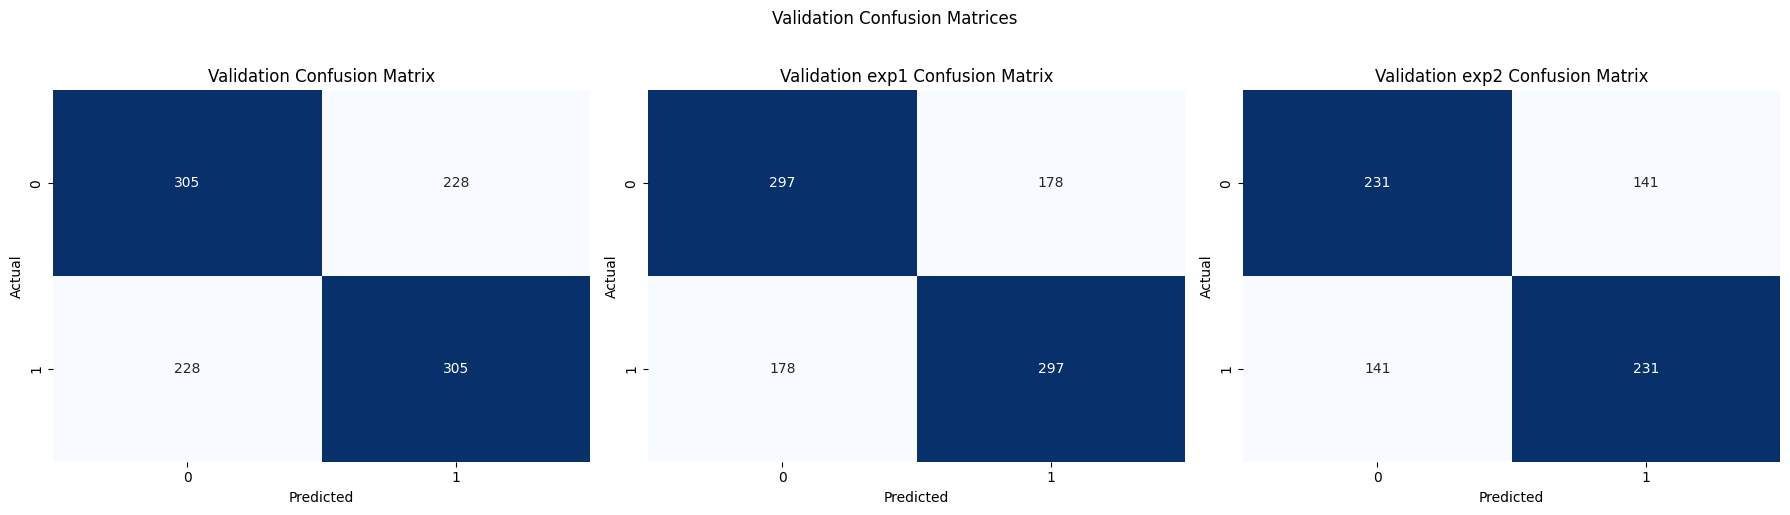

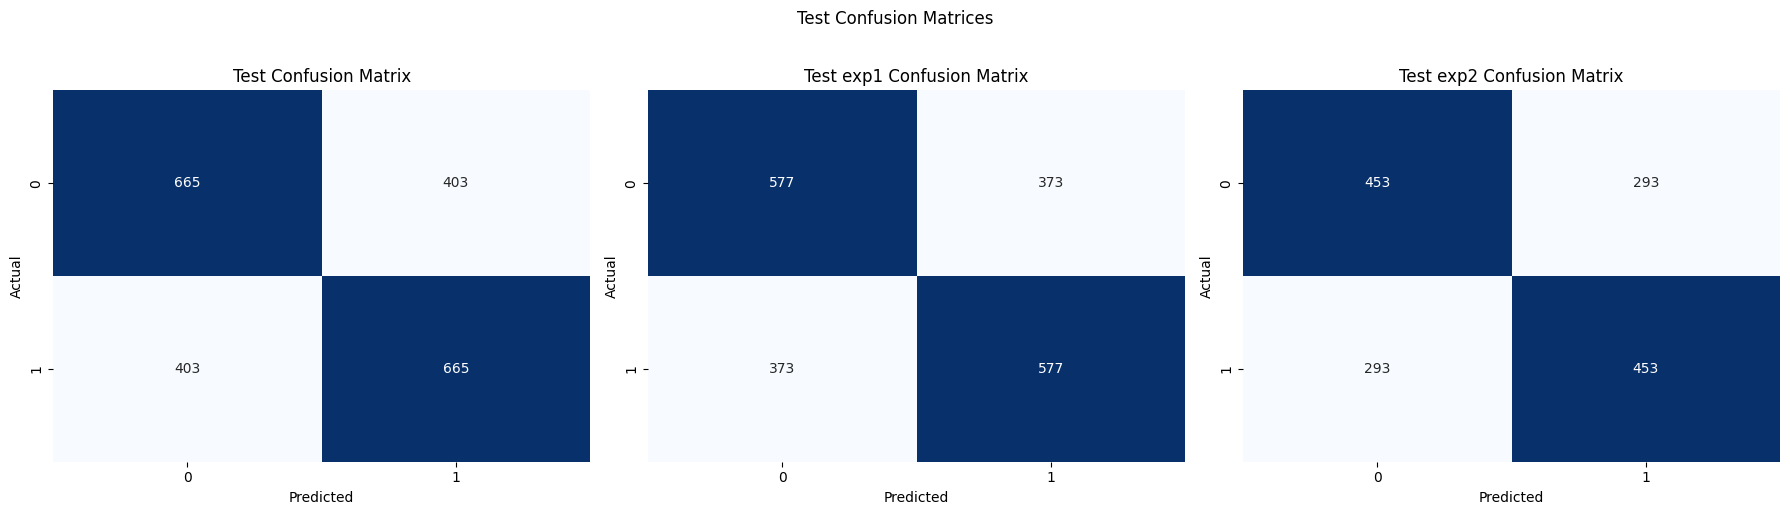

/var/folders/ll/p6v0dbfd42s1q36h2j0fz5kw0000gn/T/ipykernel_99719/2720333816.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=positive_coefs, x="coefficient", y="feature", palette="Greens_r", ax=axes[0])
/var/folders/ll/p6v0dbfd42s1q36h2j0fz5kw0000gn/T/ipykernel_99719/2720333816.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=negative_coefs, x="coefficient", y="feature", palette="Reds_r", ax=axes[1])


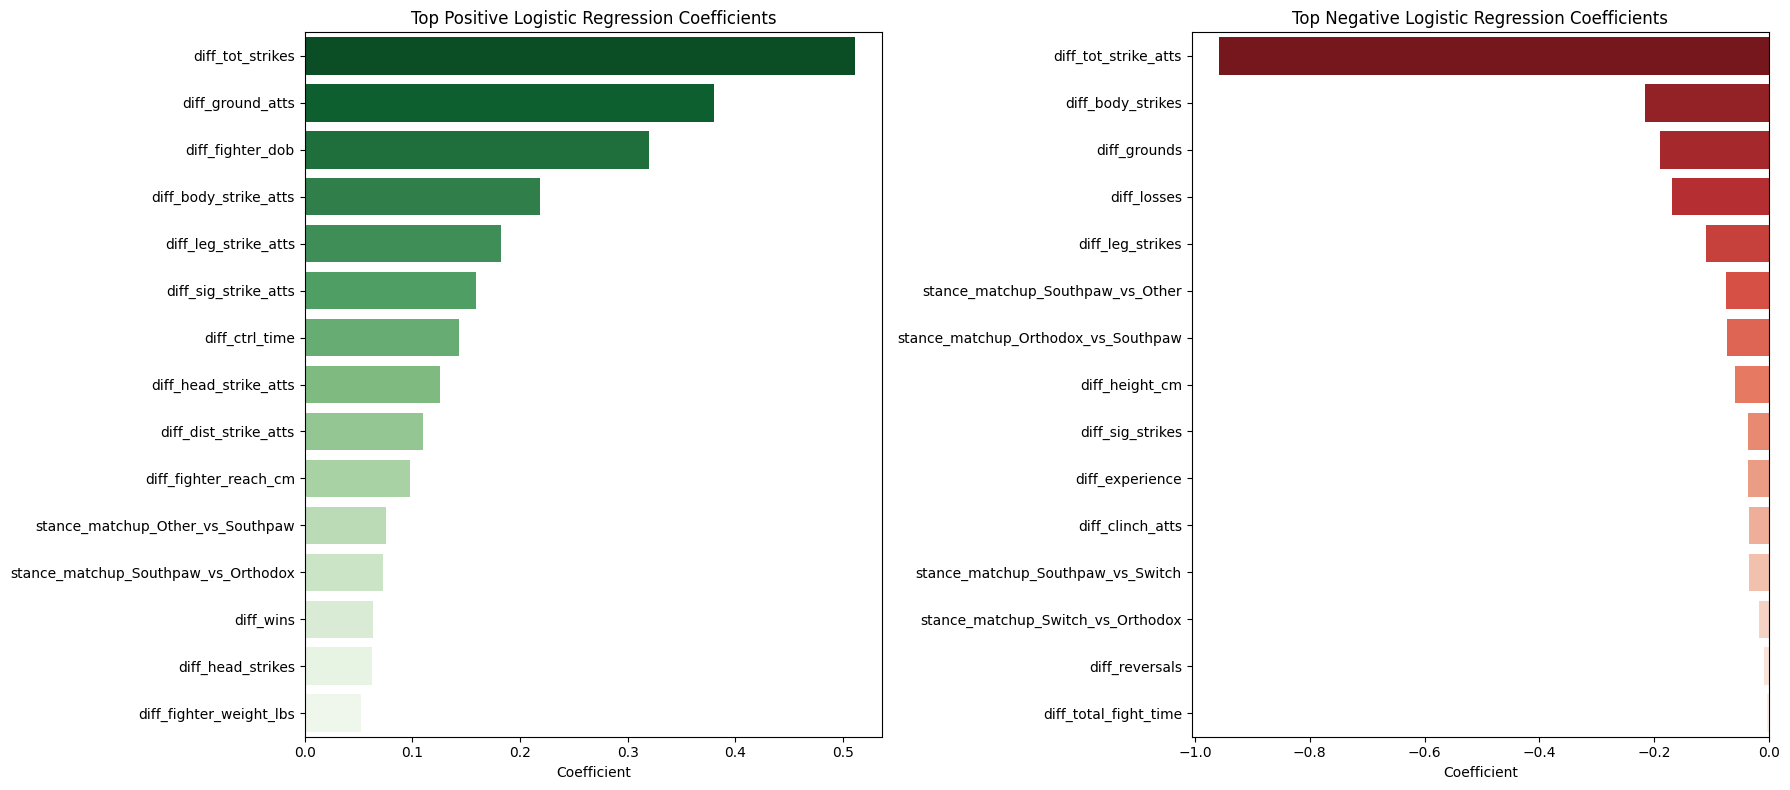

Top 15 features by absolute coefficient:


,feature,coefficient,abs_coef
20,diff_tot_strike_atts,-0.957890,0.957890
21,diff_tot_strikes,0.510566,0.510566
37,diff_ground_atts,0.379732,0.379732
15,diff_fighter_dob,0.319941,0.319941
29,diff_body_strike_atts,0.218704,0.218704
30,diff_body_strikes,-0.216024,0.216024
38,diff_grounds,-0.190193,0.190193
31,diff_leg_strike_atts,0.182702,0.182702
42,diff_losses,-0.168277,0.168277
18,diff_sig_strike_atts,0.159475,0.159475


In [31]:
validation_confusion_inputs = [
    ("Validation", y_val, val_pred),
    ("Validation exp1", y_val_exp1, val_exp1_pred),
    ("Validation exp2", y_val_exp2, val_exp2_pred),
]

test_confusion_inputs = [
    ("Test", y_test, test_pred),
    ("Test exp1", y_test_exp1, test_exp1_pred),
    ("Test exp2", y_test_exp2, test_exp2_pred),
]


def plot_confusion_group(confusion_inputs, title_prefix):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, (split_name, y_true, y_pred) in zip(axes.flatten(), confusion_inputs):
        cm = confusion_matrix(y_true, y_pred)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
        ax.set_title(f"{split_name} Confusion Matrix")
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

    fig.suptitle(f"{title_prefix} Confusion Matrices", y=1.02)
    plt.tight_layout()
    plt.show()


plot_confusion_group(validation_confusion_inputs, "Validation")
plot_confusion_group(test_confusion_inputs, "Test")

coef = pipeline.named_steps["log_reg"].coef_[0]
coef_df = pd.DataFrame({"feature": features, "coefficient": coef})
coef_df["abs_coef"] = coef_df["coefficient"].abs()

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

positive_coefs = coef_df.sort_values("coefficient", ascending=False).head(15)
negative_coefs = coef_df.sort_values("coefficient", ascending=True).head(15)

sns.barplot(data=positive_coefs, x="coefficient", y="feature", palette="Greens_r", ax=axes[0])
axes[0].set_title("Top Positive Logistic Regression Coefficients")
axes[0].set_xlabel("Coefficient")
axes[0].set_ylabel("")

sns.barplot(data=negative_coefs, x="coefficient", y="feature", palette="Reds_r", ax=axes[1])
axes[1].set_title("Top Negative Logistic Regression Coefficients")
axes[1].set_xlabel("Coefficient")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

print("Top 15 features by absolute coefficient:")
display(coef_df.sort_values("abs_coef", ascending=False).head(15))

## Feature-Focused Accuracy Plots

This code block builds feature-level diagnostics from top coefficients by plotting accuracy across value bins for top features in two separate groups:
1. Validation splits (`validation`, `validation_exp1`, `validation_exp2`)
2. Test splits (`test`, `test_exp1`, `test_exp2`)

Bins are ranges of data values grouped together to calculate model accuracy for samples in each group.

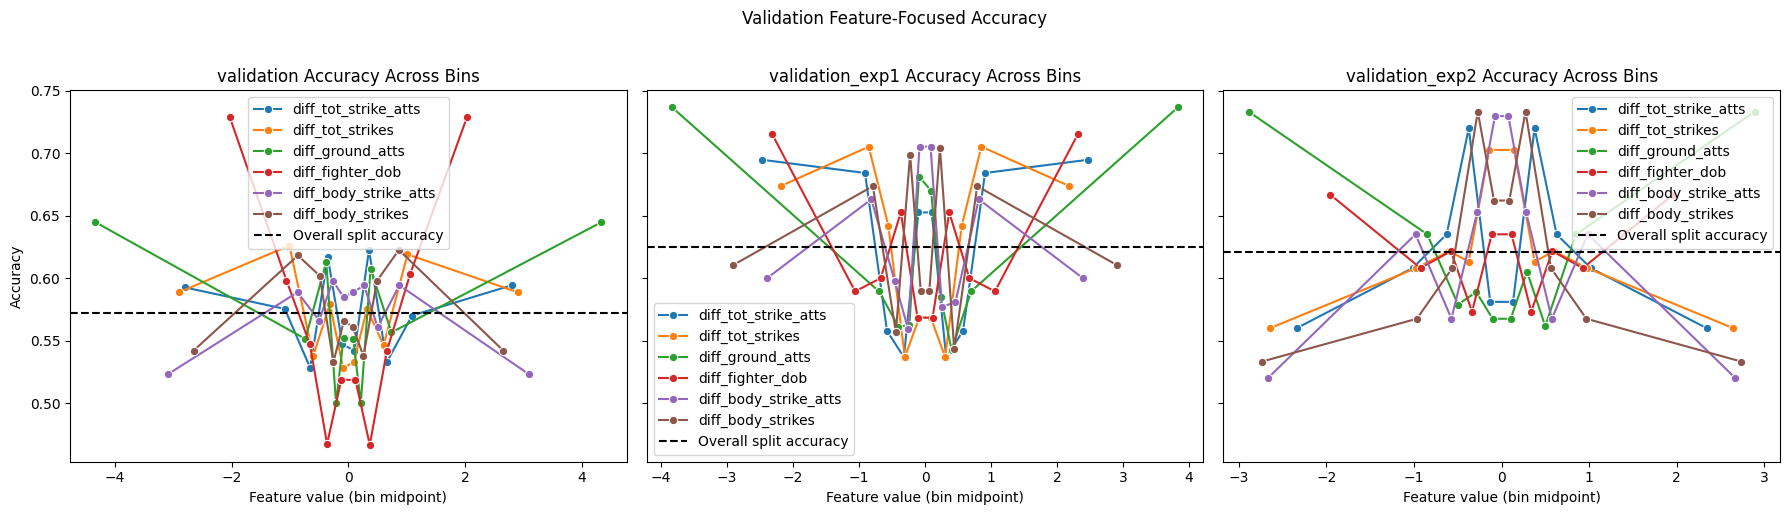

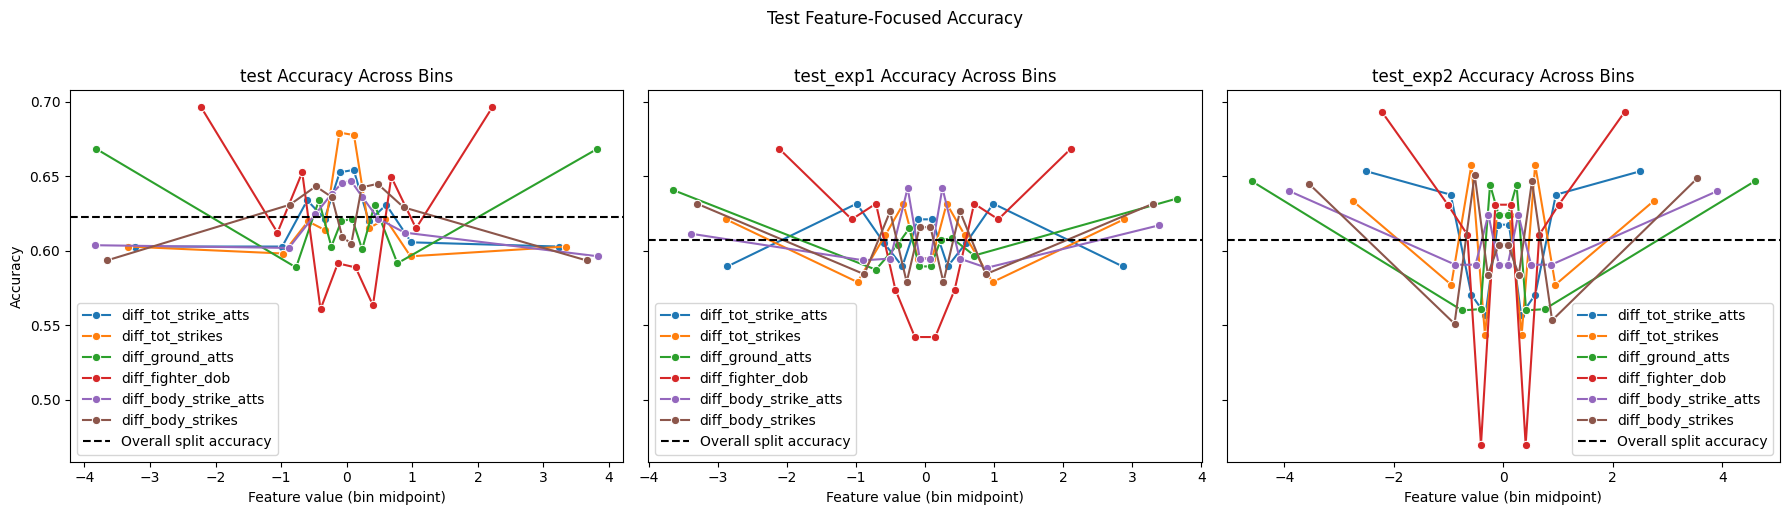

In [32]:
# Top n features for focused accuracy plots
top_n = 6
top_features = coef_df.sort_values("abs_coef", ascending=False).head(top_n)["feature"].tolist()

split_feature_inputs = {
    "validation": (x_val, y_val, val_pred),
    "validation_exp1": (x_val_exp1, y_val_exp1, val_exp1_pred),
    "validation_exp2": (x_val_exp2, y_val_exp2, val_exp2_pred),
    "test": (x_test, y_test, test_pred),
    "test_exp1": (x_test_exp1, y_test_exp1, test_exp1_pred),
    "test_exp2": (x_test_exp2, y_test_exp2, test_exp2_pred),
}

binned_rows = []
overall_acc_by_split = {}

for split_name, (x_split, y_split, pred_split) in split_feature_inputs.items():
    split_plot_df = x_split[top_features].copy()
    split_plot_df["correct"] = (pred_split == y_split.to_numpy()).astype(int)
    overall_acc_by_split[split_name] = accuracy_score(y_split, pred_split)

    for feature in top_features:
        try:
            bins = pd.qcut(split_plot_df[feature], q=10, duplicates="drop")
        except ValueError:
            continue

        feature_bins = pd.DataFrame({"bin": bins, "correct": split_plot_df["correct"]})
        summary = feature_bins.groupby("bin", observed=False)["correct"].mean().reset_index(name="accuracy")
        summary["feature"] = feature
        summary["split"] = split_name
        summary["bin_mid"] = summary["bin"].apply(lambda interval: interval.mid)
        binned_rows.append(summary)

if binned_rows:
    binned_accuracy = pd.concat(binned_rows, ignore_index=True)

    def plot_feature_accuracy_group(split_order, title_prefix):
        fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
        for ax, split_name in zip(axes.flatten(), split_order):
            split_data = binned_accuracy[binned_accuracy["split"] == split_name]
            if split_data.empty:
                ax.set_title(f"{split_name} (no plottable bins)")
                ax.axis("off")
                continue

            sns.lineplot(
                data=split_data,
                x="bin_mid",
                y="accuracy",
                hue="feature",
                marker="o",
                ax=ax,
            )
            ax.axhline(
                overall_acc_by_split[split_name],
                color="black",
                linestyle="--",
                linewidth=1.5,
                label="Overall split accuracy",
            )
            ax.set_title(f"{split_name} Accuracy Across Bins")
            ax.set_xlabel("Feature value (bin midpoint)")
            ax.set_ylabel("Accuracy")
            ax.legend(loc="best")

        fig.suptitle(f"{title_prefix} Feature-Focused Accuracy", y=1.02)
        plt.tight_layout()
        plt.show()

    plot_feature_accuracy_group(["validation", "validation_exp1", "validation_exp2"], "Validation")
    plot_feature_accuracy_group(["test", "test_exp1", "test_exp2"], "Test")
else:
    print("Could not build binned feature plots (insufficient unique values).")

## Save the Trained Model

The next code block defines the output path for the trained logistic regression model and saves it as a `.joblib` artifact for reuse in later notebooks or scripts.

In [33]:
model_path = MODEL_DIR / "logistic_regression_baseline.joblib"
# joblib.dump(pipeline, model_path)
print(f"Saved model to: {model_path}")

Saved model to: /Users/andrewmattei/Machine-Learning-Project/models/logistic_regression_baseline.joblib
